# ETH/USDT 1-Year Grid Backtest (Backtrader)

- Data: `/Users/dennis/projects/TradingTutorial/data/eth_usdt_1m_1y.csv`
- Grid range: `2000 - 6000`
- Grid size: `80`
- Initial cash: `10000 USDT`


In [6]:
import backtrader as bt
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque

DATA_PATH = '/Users/dennis/projects/TradingTutorial/data/eth_usdt_1m_1y.csv'
GRID_LOWER = 1500
GRID_UPPER = 6000
GRID_SIZE = 80
INITIAL_CASH = 10000
COMMISSION = 0.001  # 0.1%


In [7]:
df = pd.read_csv(DATA_PATH)
df['datetime'] = pd.to_datetime(df['datetime'], utc=True).dt.tz_convert(None)
df = df.sort_values('datetime').set_index('datetime')
df = df[['open', 'high', 'low', 'close', 'volume']].dropna()

df.head(), df.tail(), df.shape

(                        open     high      low    close     volume
 datetime                                                          
 2025-04-03 12:24:00  1794.53  1795.00  1793.67  1793.88   153.1051
 2025-04-03 12:25:00  1793.89  1793.89  1791.09  1791.90   540.9679
 2025-04-03 12:26:00  1791.89  1793.16  1790.46  1790.84   367.3421
 2025-04-03 12:27:00  1790.83  1791.32  1786.49  1787.72  1082.1948
 2025-04-03 12:28:00  1787.71  1788.80  1787.04  1787.13   340.8351,
                         open     high      low    close   volume
 datetime                                                        
 2026-04-03 12:21:00  2061.54  2061.55  2060.92  2061.06  18.2334
 2026-04-03 12:22:00  2061.07  2061.69  2060.06  2060.06  72.4738
 2026-04-03 12:23:00  2060.07  2060.58  2059.79  2059.95  60.9519
 2026-04-03 12:24:00  2059.94  2060.12  2059.45  2060.11  14.9177
 2026-04-03 12:25:00  2060.12  2062.30  2060.12  2062.29  28.9824,
 (523510, 5))

In [8]:
class GridStrategy(bt.Strategy):
    params = dict(
        lower=2000.0,
        upper=6000.0,
        grid_size=80.0,
        commission=0.001,
    )

    def __init__(self):
        self.close = self.datas[0].close
        self.levels = np.arange(self.p.lower, self.p.upper + self.p.grid_size, self.p.grid_size)
        self.grid_count = int((self.p.upper - self.p.lower) / self.p.grid_size)
        self.trade_cash = self.broker.getcash() / max(1, self.grid_count)

        self.last_price = None
        self.open_lots = deque()
        self.pending_sells = {}

        self.value_history = []
        self.dt_history = []

    def notify_order(self, order):
        if order.status in [order.Completed]:
            action = order.info.get('action', None)
            if action == 'buy':
                target = order.info['target']
                self.open_lots.append({'size': order.executed.size, 'target': target})
            elif action == 'sell':
                self.pending_sells.pop(order.ref, None)

        if order.status in [order.Canceled, order.Margin, order.Rejected]:
            action = order.info.get('action', None)
            if action == 'sell' and order.ref in self.pending_sells:
                # Put back the lot if sell failed
                self.open_lots.appendleft(self.pending_sells.pop(order.ref))

    def _crossed_down_levels(self, prev_price, curr_price):
        return [lvl for lvl in self.levels if curr_price <= lvl < prev_price]

    def _crossed_up_levels(self, prev_price, curr_price):
        return [lvl for lvl in self.levels if prev_price < lvl <= curr_price]

    def next(self):
        price = float(self.close[0])

        self.dt_history.append(self.datas[0].datetime.datetime(0))
        self.value_history.append(self.broker.getvalue())

        if self.last_price is None:
            self.last_price = price
            return

        # Down move: buy one lot per crossed grid level within range
        if price < self.last_price:
            for lvl in self._crossed_down_levels(self.last_price, price):
                if not (self.p.lower <= lvl <= self.p.upper):
                    continue
                if self.broker.getcash() < self.trade_cash:
                    break
                size = self.trade_cash / price
                o = self.buy(size=size)
                o.addinfo(action='buy', target=lvl + self.p.grid_size)

        # Up move: sell one existing lot when its target grid is crossed
        elif price > self.last_price:
            for lvl in self._crossed_up_levels(self.last_price, price):
                candidate_idx = None
                for i, lot in enumerate(self.open_lots):
                    if lot['target'] <= lvl:
                        candidate_idx = i
                        break
                if candidate_idx is None:
                    continue

                lot = self.open_lots[candidate_idx]
                del self.open_lots[candidate_idx]
                o = self.sell(size=lot['size'])
                o.addinfo(action='sell')
                self.pending_sells[o.ref] = lot

        self.last_price = price


In [9]:
cerebro = bt.Cerebro(stdstats=False)

data_feed = bt.feeds.PandasData(dataname=df)
cerebro.adddata(data_feed)

cerebro.addstrategy(
    GridStrategy,
    lower=GRID_LOWER,
    upper=GRID_UPPER,
    grid_size=GRID_SIZE,
    commission=COMMISSION,
)

cerebro.broker.setcash(INITIAL_CASH)
cerebro.broker.setcommission(commission=COMMISSION)
cerebro.broker.set_coc(True)  # cheat-on-close

cerebro.addanalyzer(bt.analyzers.Returns, _name='returns')
cerebro.addanalyzer(bt.analyzers.DrawDown, _name='drawdown')
cerebro.addanalyzer(bt.analyzers.TradeAnalyzer, _name='trades')

results = cerebro.run()
strat = results[0]

start_value = INITIAL_CASH
end_value = cerebro.broker.getvalue()
pnl = end_value - start_value
pnl_pct = pnl / start_value * 100

ret = strat.analyzers.returns.get_analysis()
dd = strat.analyzers.drawdown.get_analysis()
tr = strat.analyzers.trades.get_analysis()

print(f'Start Value: {start_value:,.2f} USDT')
print(f'End Value:   {end_value:,.2f} USDT')
print(f'PnL:         {pnl:,.2f} USDT ({pnl_pct:.2f}%)')
print(f'Max Drawdown:{dd.max.drawdown:.2f}%')

total_trades = tr.total.closed if hasattr(tr, 'total') and hasattr(tr.total, 'closed') else 0
won = tr.won.total if hasattr(tr, 'won') and hasattr(tr.won, 'total') else 0
lost = tr.lost.total if hasattr(tr, 'lost') and hasattr(tr.lost, 'total') else 0

print(f'Closed Trades: {total_trades}')
print(f'Won / Lost:    {won} / {lost}')

Start Value: 10,000.00 USDT
End Value:   11,451.81 USDT
PnL:         1,451.81 USDT (14.52%)
Max Drawdown:64.40%


KeyError: 

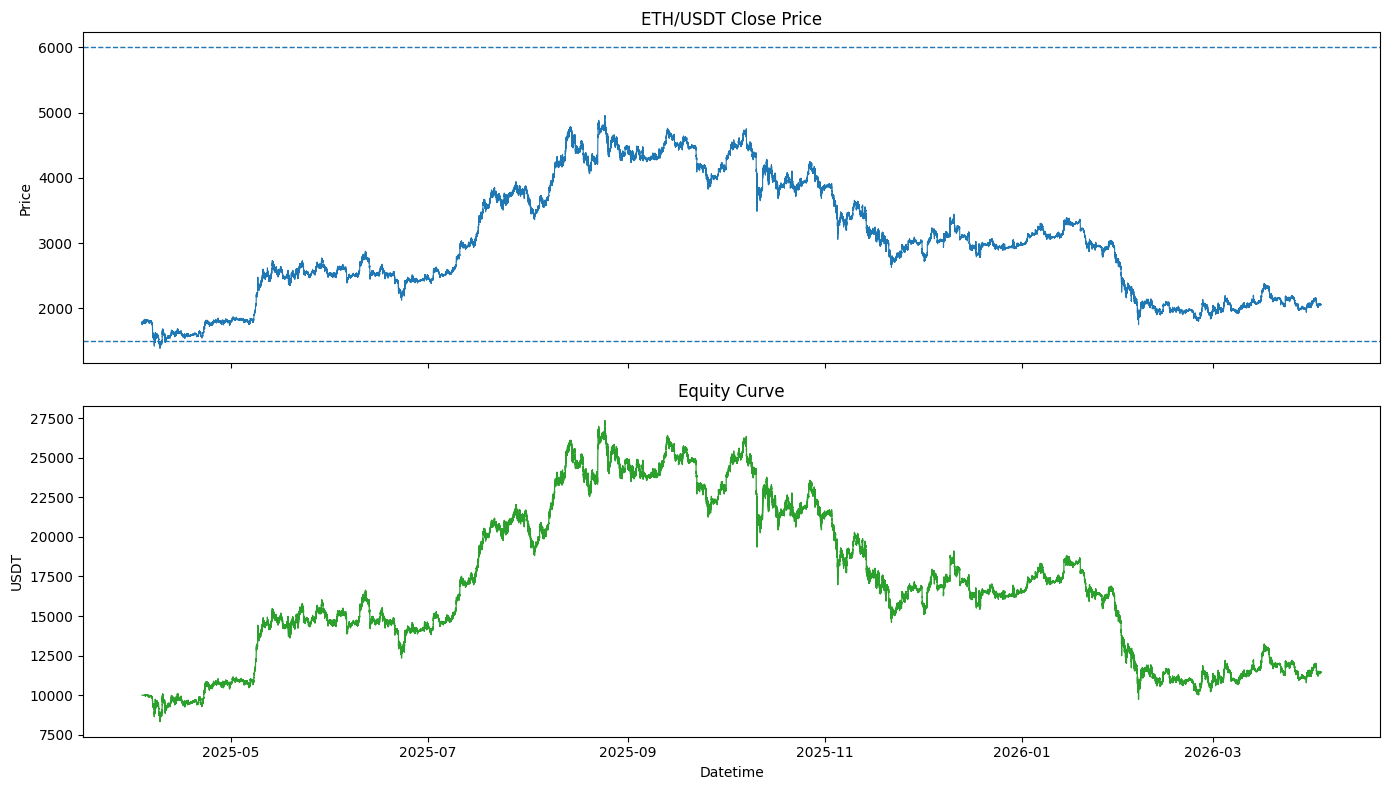

In [10]:
eq = pd.DataFrame({'datetime': strat.dt_history, 'equity': strat.value_history}).drop_duplicates('datetime')
eq = eq.set_index('datetime')

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

axes[0].plot(df.index, df['close'], linewidth=0.8)
axes[0].axhline(GRID_LOWER, linestyle='--', linewidth=1)
axes[0].axhline(GRID_UPPER, linestyle='--', linewidth=1)
axes[0].set_title('ETH/USDT Close Price')
axes[0].set_ylabel('Price')

axes[1].plot(eq.index, eq['equity'], color='tab:green', linewidth=0.9)
axes[1].set_title('Equity Curve')
axes[1].set_ylabel('USDT')
axes[1].set_xlabel('Datetime')

plt.tight_layout()
plt.show()